In [1]:
import pandas as pd
from pathlib import Path


AUTHENTIC_ROOT = Path("dataset_split/train/authentic")
FORENSIC_ROOT = Path("dataset_split/train/forged")

material_classes = {
    "Biological",
    "Fibres",
    "Nanowires",
    "Particles",
    "Porous_Sponge",
    "Powder"
}

device_classes = {
    "Films_Coated_Surface",
    "MEMS_devices_and_electrodes",
    "Patterned_surface",
    "Tips"
}


records = []

# -----------------------------------
# Add Authentic Images
# -----------------------------------

for class_dir in AUTHENTIC_ROOT.iterdir():

    if not class_dir.is_dir():
        continue

    defect_type = class_dir.name

    if defect_type in material_classes:
        domain = "Material"
    else:
        domain = "Device"

    for img_path in class_dir.glob("*"):

        records.append({

            "image_name":
                img_path.name,

            "image_path":
                str(img_path),

            "defect_type":
                defect_type,

            "domain":
                domain,

            "authenticity":
                "Authentic",

            "mask_path":
                ""

        })


# -----------------------------------
# Add Forged Images
# -----------------------------------

for forgery_type_dir in FORENSIC_ROOT.iterdir():

    if not forgery_type_dir.is_dir():
        continue

    forgery_type = forgery_type_dir.name

    for class_dir in forgery_type_dir.iterdir():

        if not class_dir.is_dir():
            continue

        defect_type = class_dir.name

        domain = (
            "Material"
            if defect_type in material_classes
            else "Device"
        )

        for img_path in class_dir.glob("*"):

            mask_path = str(

                Path(
                    "dataset_split/train/masks"
                )

                / forgery_type
                / defect_type
                / img_path.name
            )

            records.append({

                "image_name":
                    img_path.name,

                "image_path":
                    str(img_path),

                "defect_type":
                    defect_type,

                "domain":
                    domain,

                "authenticity":
                    forgery_type,

                "mask_path":
                    mask_path
            })
# -----------------------------------
# Create DataFrame
# -----------------------------------

df = pd.DataFrame(records)

print(df.head())

# -----------------------------------
# Save CSV
# -----------------------------------

df.to_csv(
    "SEM_forensic_metadata.csv",
    index=False
)

print(
    f"\nTotal records: {len(df)}"
)

print(
    "\nSaved as SEM_forensic_metadata.csv"
)

                                image_name  \
0  L4_c0881a70509cbc98a7e8eff93d86f2f9.jpg   
1  L4_29ad5d70767fc5a51b0ce4f232fae40e.jpg   
2  L4_80ed47ecd9b707cf5210fd548f7c7286.jpg   
3  L4_a32d5b70c1374299f1866f966f3c081a.jpg   
4  L4_b3e693c0c3ab2d746d6600bcd8981c44.jpg   

                                          image_path defect_type    domain  \
0  dataset_split/train/authentic/Powder/L4_c0881a...      Powder  Material   
1  dataset_split/train/authentic/Powder/L4_29ad5d...      Powder  Material   
2  dataset_split/train/authentic/Powder/L4_80ed47...      Powder  Material   
3  dataset_split/train/authentic/Powder/L4_a32d5b...      Powder  Material   
4  dataset_split/train/authentic/Powder/L4_b3e693...      Powder  Material   

  authenticity mask_path  
0    Authentic            
1    Authentic            
2    Authentic            
3    Authentic            
4    Authentic            

Total records: 3600

Saved as SEM_forensic_metadata.csv


In [2]:
#pip install torch torchvision timm opencv-python scikit-image pillow

In [3]:
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

from PIL import Image
from skimage.feature import local_binary_pattern

import timm

from torchvision.models import efficientnet_b0

import pandas as pd

import torch
from torch.utils.data import Dataset
from torchvision import transforms
from torch.utils.data import DataLoader
import os

In [4]:
from io import BytesIO
class ForensicPreprocessor:

    def __init__(self,
                 lbp_radius=2,
                 lbp_points=16):

        self.radius = lbp_radius
        self.points = lbp_points

    def normalize(self, img):

        img = img.astype(np.float32)
    
        min_val = img.min()
        max_val = img.max()
    
        if max_val - min_val < 1e-8:
            return np.zeros_like(img, dtype=np.float32)
    
        return (
            img - min_val
        ) / (
            max_val - min_val
        )

    def residual_map(self, img):

        blur = cv2.GaussianBlur(
            img,
            (5,5),
            0
        )

        residual = cv2.absdiff(
            img,
            blur
        )

        return self.normalize(residual)

    def fft_map(self, img):

        f = np.fft.fft2(img)

        fshift = np.fft.fftshift(f)

        magnitude = np.log(
            np.abs(fshift)+1
        )

        return self.normalize(magnitude)

    def lbp_map(self, img):

        lbp = local_binary_pattern(
            img,
            P=self.points,
            R=self.radius,
            method='uniform'
        )

        return self.normalize(lbp)

    def ela_map(self, img):
    
        buffer = BytesIO()
    
        Image.fromarray(img).save(
            buffer,
            format="JPEG",
            quality=90
        )
    
        buffer.seek(0)
    
        recompressed = np.array(
            Image.open(buffer).convert("L")
        )
    
        ela = cv2.absdiff(
            img,
            recompressed
        )
    
        return self.normalize(ela)

    def process(self, img):

        residual = self.residual_map(img)

        fft = self.fft_map(img)

        lbp = self.lbp_map(img)

        ela = self.ela_map(img)

        stacked = np.stack([
            residual,
            fft,
            lbp,
            ela
        ], axis=0)

        return stacked

In [5]:
class CNNBranch(nn.Module):

    def __init__(self):

        super().__init__()

        backbone = efficientnet_b0(
            weights="DEFAULT"
        )

        backbone.classifier = nn.Identity()

        self.backbone = backbone

    def forward(self,x):

        return self.backbone(x)

In [6]:
import torch.nn.functional as F

class ViTBranch(nn.Module):

    def __init__(self):
        super().__init__()

        self.vit = timm.create_model(
            'vit_base_patch16_224',
            pretrained=True,
            num_classes=0
        )

    def forward(self, x):

        x = F.interpolate(
            x,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        return self.vit(x)

In [7]:
class MorphologyBranch(nn.Module):

    def __init__(self):

        super().__init__()

        self.cnn = CNNBranch()

        self.vit = ViTBranch()

        self.fc = nn.Sequential(

            nn.Linear(
                1280+768,
                1024
            ),

            nn.ReLU(),

            nn.Dropout(0.3)
        )

    def forward(self,x):

        cnn_feat = self.cnn(x)

        vit_feat = self.vit(x)

        combined = torch.cat(
            [
                cnn_feat,
                vit_feat
            ],
            dim=1
        )

        morphology_feat = self.fc(
            combined
        )

        return morphology_feat

In [8]:
class ForensicCNN(nn.Module):

    def __init__(self):

        super().__init__()

        # --------------------------------
        # Convolutional feature extractor
        # --------------------------------

        self.conv1 = nn.Sequential(

            nn.Conv2d(
                4,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(),

            nn.MaxPool2d(2)
        )

        self.conv2 = nn.Sequential(

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(),

            nn.MaxPool2d(2)
        )

        self.conv3 = nn.Sequential(

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(),

            nn.MaxPool2d(2)
        )

        # --------------------------------
        # Global pooling for classification
        # --------------------------------

        self.global_pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Linear(
            128,
            256
        )

    def forward(
        self,
        x,
        return_feature_map=False
    ):

        x = self.conv1(x)

        x = self.conv2(x)

        x = self.conv3(x)

        # --------------------------------
        # IMPORTANT:
        # Preserve spatial feature map
        # --------------------------------

        feature_map = x

        # --------------------------------
        # Classification feature
        # --------------------------------

        pooled = self.global_pool(
            feature_map
        )

        pooled = pooled.view(
            pooled.size(0),
            -1
        )

        forensic_feature = self.fc(
            pooled
        )

        if return_feature_map:

            return (
                forensic_feature,
                feature_map
            )

        return forensic_feature

In [9]:
class LocalizationDecoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.decoder = nn.Sequential(

            # 128 -> 64
            nn.Conv2d(
                128,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(),

            nn.Upsample(
                scale_factor=2,
                mode="bilinear",
                align_corners=False
            ),

            # 64 -> 32
            nn.Conv2d(
                64,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(),

            nn.Upsample(
                scale_factor=2,
                mode="bilinear",
                align_corners=False
            ),

            # 32 -> 16
            nn.Conv2d(
                32,
                16,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(16),

            nn.ReLU(),

            nn.Upsample(
                scale_factor=2,
                mode="bilinear",
                align_corners=False
            ),

            # Final mask
            nn.Conv2d(
                16,
                1,
                kernel_size=1
            )
        )

    def forward(
        self,
        feature_map,
        target_size
    ):

        x = self.decoder(
            feature_map
        )

        # Ensure exact same dimensions
        # as ground truth mask

        x = F.interpolate(
            x,
            size=target_size,
            mode="bilinear",
            align_corners=False
        )

        return x

In [10]:
class FeatureFusion(nn.Module):

    def __init__(self):
        super().__init__()

        self.morph_proj = nn.Sequential(
            nn.Linear(1024, 512),
            nn.LayerNorm(512),
            nn.ReLU()
        )

        self.forensic_proj = nn.Sequential(
            nn.Linear(256, 512),
            nn.LayerNorm(512),
            nn.ReLU()
        )

        self.gate = nn.Sequential(
            nn.Linear(1024, 512),
            nn.Sigmoid()
        )

        self.output_fc = nn.Sequential(
            nn.Linear(512, 512),
            nn.LayerNorm(512),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

    def forward(
        self,
        morphology_feat,
        forensic_feat
    ):

        morphology_feat = self.morph_proj(
            morphology_feat
        )

        forensic_feat = self.forensic_proj(
            forensic_feat
        )

        combined = torch.cat(
            [
                morphology_feat,
                forensic_feat
            ],
            dim=1
        )

        gate = self.gate(combined)

        fused = (
            gate * morphology_feat
            +
            (1.0 - gate) * forensic_feat
        )

        fused = self.output_fc(fused)

        return fused

In [11]:
class SEMFeatureExtractor(nn.Module):

    def __init__(self):

        super().__init__()

        self.morphology = (
            MorphologyBranch()
        )

        self.forensic = (
            ForensicCNN()
        )

        self.fusion = (
            FeatureFusion()
        )

    def forward(
        self,
        sem_image,
        forensic_maps
    ):

        # ==================================
        # Morphology branch
        # ==================================

        morphology_feat = (
            self.morphology(
                sem_image
            )
        )

        # ==================================
        # Forensic branch
        # ==================================

        (
            forensic_feat,
            forensic_feature_map
        ) = self.forensic(
            forensic_maps,
            return_feature_map=True
        )

        # ==================================
        # Gated fusion
        # ==================================

        fused_feat = self.fusion(
            morphology_feat,
            forensic_feat
        )

        return {

            "morphology_features":
                morphology_feat,

            "forensic_features":
                forensic_feat,

            "forensic_feature_map":
                forensic_feature_map,

            "fused_features":
                fused_feat
        }

In [12]:
DEFECT_MAP = {
    "Biological":0,
    "Fibres":1,
    "Films_Coated_Surface":2,
    "MEMS_devices_and_electrodes":3,
    "Nanowires":4,
    "Particles":5,
    "Patterned_surface":6,
    "Porous_Sponge":7,
    "Powder":8,
    "Tips":9
}

DOMAIN_MAP = {
    "Material":0,
    "Device":1
}

AUTH_MAP = {
    "Authentic":0,
    "copy_move":1,
    "splicing":2,
    "synthetic":3,
    "contrast":4
}

In [13]:
class SEMForensicDataset(Dataset):

    def __init__(
        self,
        csv_file,
        forensic_preprocessor
    ):

        self.df = pd.read_csv(
            csv_file
        )

        self.preprocessor = (
            forensic_preprocessor
        )

        self.transform = transforms.Compose([

            transforms.ToPILImage(),

            transforms.Grayscale(
                num_output_channels=3
            ),

            transforms.ToTensor(),

            transforms.Normalize(
                mean=[0.5, 0.5, 0.5],
                std=[0.5, 0.5, 0.5]
            )
        ])

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # ==================================
        # Load SEM image
        # ==================================

        img_path = row["image_path"]

        img = cv2.imread(
            img_path,
            cv2.IMREAD_GRAYSCALE
        )

        if img is None:

            raise RuntimeError(
                f"Could not read image: {img_path}"
            )

        # ==================================
        # SEM image tensor
        # ==================================

        sem_tensor = self.transform(
            img
        )

        # ==================================
        # Forensic maps
        # ==================================

        forensic_maps = (
            self.preprocessor.process(
                img
            )
        )

        forensic_tensor = torch.tensor(
            forensic_maps,
            dtype=torch.float32
        )

        # ==================================
        # Labels
        # ==================================

        defect_label = DEFECT_MAP[
            row["defect_type"]
        ]

        domain_label = DOMAIN_MAP[
            row["domain"]
        ]

        auth_label = AUTH_MAP[
            row["authenticity"]
        ]

        # ==================================
        # Ground truth manipulation mask
        # ==================================

        mask_path = str(
            row["mask_path"]
        )

        if (
            mask_path
            and mask_path != "nan"
            and os.path.exists(mask_path)
        ):

            mask = cv2.imread(
                mask_path,
                cv2.IMREAD_GRAYSCALE
            )

            if mask is None:

                raise RuntimeError(
                    f"Could not read mask: {mask_path}"
                )

            # Convert to binary
            mask = (
                mask > 127
            ).astype(np.float32)

        else:

            # Authentic images have no manipulation
            # therefore the GT mask is all zeros

            mask = np.zeros_like(
                img,
                dtype=np.float32
            )

        # ----------------------------------
        # Add channel dimension
        # ----------------------------------

        mask = torch.tensor(
            mask,
            dtype=torch.float32
        ).unsqueeze(0)

        # ==================================
        # Return sample
        # ==================================

        sample = {

            "sem_image":
                sem_tensor,

            "forensic_maps":
                forensic_tensor,

            "mask":
                mask,

            "defect":
                torch.tensor(
                    defect_label,
                    dtype=torch.long
                ),

            "domain":
                torch.tensor(
                    domain_label,
                    dtype=torch.long
                ),

            "auth":
                torch.tensor(
                    auth_label,
                    dtype=torch.long
                )
        }

        return sample

In [14]:
preprocessor = ForensicPreprocessor()

dataset = SEMForensicDataset(

    csv_file=
    "SEM_forensic_metadata.csv",

    forensic_preprocessor=
    preprocessor
)

In [15]:
train_loader = DataLoader(

    dataset,

    batch_size=16,

    shuffle=True,

    num_workers=0
)

In [16]:
class MultiTaskClassifier(nn.Module):

    def __init__(self,
                 input_dim=512):

        super().__init__()

        # Shared representation

        self.shared = nn.Sequential(

            nn.Linear(input_dim, 256),

            nn.BatchNorm1d(256),

            nn.ReLU(),

            nn.Dropout(0.3)
        )

        # -----------------------
        # Defect Head
        # -----------------------

        self.defect_head = nn.Sequential(

            nn.Linear(256,128),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(128,10)
        )

        # -----------------------
        # Domain Head
        # -----------------------

        self.domain_head = nn.Sequential(

            nn.Linear(256,64),

            nn.ReLU(),

            nn.Linear(64,2)
        )

        # -----------------------
        # Authenticity Head
        # -----------------------

        self.auth_head = nn.Sequential(

            nn.Linear(256,128),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(128,5)
        )

    def forward(self,x):

        shared_feat = self.shared(x)

        defect_logits = self.defect_head(
            shared_feat
        )

        domain_logits = self.domain_head(
            shared_feat
        )

        auth_logits = self.auth_head(
            shared_feat
        )

        return {

            "defect_logits":
                defect_logits,

            "domain_logits":
                domain_logits,

            "auth_logits":
                auth_logits
        }

In [17]:
class ForensicSEMModel(nn.Module):

    def __init__(
        self,
        feature_extractor
    ):

        super().__init__()

        self.feature_extractor = (
            feature_extractor
        )

        self.classifier = (
            MultiTaskClassifier()
        )

        # ----------------------------------
        # Supervised localization branch
        # ----------------------------------

        self.localization_decoder = (
            LocalizationDecoder()
        )

    def forward(
        self,
        sem_image,
        forensic_maps
    ):

        features = (
            self.feature_extractor(
                sem_image,
                forensic_maps
            )
        )

        # ==================================
        # Classification
        # ==================================

        fused_features = features[
            "fused_features"
        ]

        outputs = self.classifier(
            fused_features
        )

        # ==================================
        # Localization
        # ==================================

        feature_map = features[
            "forensic_feature_map"
        ]

        target_size = (
            forensic_maps.shape[-2:]
        )

        mask_logits = (
            self.localization_decoder(
                feature_map,
                target_size
            )
        )

        # ==================================
        # Add localization output
        # ==================================

        outputs[
            "mask_logits"
        ] = mask_logits

        return outputs

In [18]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

feature_extractor = SEMFeatureExtractor()

model = ForensicSEMModel(
    feature_extractor
).to(device)

In [19]:
from sklearn.utils.class_weight import compute_class_weight

train_defect_labels = []
train_domain_labels = []
train_auth_labels = []

for batch in train_loader:

    train_defect_labels.extend(
        batch["defect"].cpu().numpy()
    )

    train_domain_labels.extend(
        batch["domain"].cpu().numpy()
    )

    train_auth_labels.extend(
        batch["auth"].cpu().numpy()
    )

train_defect_labels = np.array(train_defect_labels)
train_domain_labels = np.array(train_domain_labels)
train_auth_labels = np.array(train_auth_labels)

defect_classes = np.unique(train_defect_labels)

defect_weights = compute_class_weight(
    class_weight="balanced",
    classes=defect_classes,
    y=train_defect_labels
)

defect_weights = torch.tensor(
    defect_weights,
    dtype=torch.float32
).to(device)

domain_classes = np.unique(train_domain_labels)

domain_weights = compute_class_weight(
    class_weight="balanced",
    classes=domain_classes,
    y=train_domain_labels
)

domain_weights = torch.tensor(
    domain_weights,
    dtype=torch.float32
).to(device)

auth_classes = np.unique(train_auth_labels)

auth_weights = compute_class_weight(
    class_weight="balanced",
    classes=auth_classes,
    y=train_auth_labels
)

auth_weights = torch.tensor(
    auth_weights,
    dtype=torch.float32
).to(device)

In [20]:
def dice_loss(
    logits,
    targets,
    smooth=1.0
):

    probs = torch.sigmoid(
        logits
    )

    probs = probs.view(
        probs.size(0),
        -1
    )

    targets = targets.view(
        targets.size(0),
        -1
    )

    intersection = (
        probs * targets
    ).sum(dim=1)

    dice = (
        2.0 * intersection
        + smooth
    ) / (
        probs.sum(dim=1)
        + targets.sum(dim=1)
        + smooth
    )

    return (
        1.0 - dice
    ).mean()

In [21]:
def localization_loss(
    mask_logits,
    mask_targets
):

    bce = F.binary_cross_entropy_with_logits(
        mask_logits,
        mask_targets
    )

    dice = dice_loss(
        mask_logits,
        mask_targets
    )

    return (
        bce + dice
    )

In [22]:
def compute_loss(
    outputs,
    defect_labels,
    domain_labels,
    auth_labels,
    mask_targets,
    lambda_loc=1.0
):

    # -------------------------------
    # Defect
    # -------------------------------

    defect_loss_fn = nn.CrossEntropyLoss(
        label_smoothing=0.05
    )

    loss_defect = defect_loss_fn(
        outputs["defect_logits"],
        defect_labels
    )

    # -------------------------------
    # Domain
    # -------------------------------

    domain_loss_fn = nn.CrossEntropyLoss()

    loss_domain = domain_loss_fn(
        outputs["domain_logits"],
        domain_labels
    )

    # -------------------------------
    # Authenticity
    # -------------------------------

    auth_loss_fn = nn.CrossEntropyLoss(
        weight=auth_weights
    )

    loss_auth = auth_loss_fn(
        outputs["auth_logits"],
        auth_labels
    )

    # -------------------------------
    # Localization
    # -------------------------------

    loss_localization = localization_loss(
        outputs["mask_logits"],
        mask_targets
    )

    # -------------------------------
    # Total
    # -------------------------------

    total_loss = (

        loss_defect
        + loss_domain
        + loss_auth
        + lambda_loc * loss_localization
    )

    loss_dict = {

        "total":
            total_loss,

        "defect":
            loss_defect,

        "domain":
            loss_domain,

        "auth":
            loss_auth,

        "localization":
            loss_localization
    }

    return loss_dict

In [23]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=50,
    eta_min=1e-6
)

In [24]:
import time
import torch
import numpy as np

num_epochs = 50

lambda_loc = 1.0

PRINT_EVERY = 600

for epoch in range(num_epochs):

    model.train()

    epoch_start_time = time.time()

    running_loss = 0.0
    running_defect_loss = 0.0
    running_domain_loss = 0.0
    running_auth_loss = 0.0
    running_loc_loss = 0.0

    samples_processed = 0

    total_samples = len(train_loader.dataset)

    total_batches = len(train_loader)

    print("\n" + "=" * 70)

    print(f"Starting Epoch [{epoch+1}/{num_epochs}]")

    print(f"Total training samples: {total_samples}")

    print(f"Total batches: {total_batches}")

    print("=" * 70)

    for batch_idx, batch in enumerate(train_loader):

        batch_start_time = time.time()

        # ==================================
        # Load batch
        # ==================================

        sem_images = batch["sem_image"].to(device)

        forensic_maps = batch["forensic_maps"].to(device)

        defect_labels = batch["defect"].long().to(device)

        domain_labels = batch["domain"].long().to(device)

        auth_labels = batch["auth"].long().to(device)

        mask_targets = batch["mask"].float().to(device)

        batch_size = sem_images.size(0)

        # ==================================
        # Forward
        # ==================================

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            sem_images,
            forensic_maps
        )

        # ==================================
        # Loss
        # ==================================

        losses = compute_loss(
            outputs,
            defect_labels,
            domain_labels,
            auth_labels,
            mask_targets,
            lambda_loc=lambda_loc
        )

        loss = losses["total"]

        # ==================================
        # Backpropagation
        # ==================================

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        # ==================================
        # Update statistics
        # ==================================

        running_loss += loss.item() * batch_size

        running_defect_loss += (
            losses["defect"].item() * batch_size
        )

        running_domain_loss += (
            losses["domain"].item() * batch_size
        )

        running_auth_loss += (
            losses["auth"].item() * batch_size
        )

        running_loc_loss += (
            losses["localization"].item() * batch_size
        )

        samples_processed += batch_size

        # ==================================
        # Progress print every 600 samples
        # ==================================

        if (
            samples_processed // PRINT_EVERY
            >
            (samples_processed - batch_size) // PRINT_EVERY
            or batch_idx == total_batches - 1
        ):

            elapsed_time = (
                time.time() - epoch_start_time
            )

            progress = (
                samples_processed / total_samples
            ) * 100

            avg_loss = (
                running_loss / samples_processed
            )

            avg_defect = (
                running_defect_loss / samples_processed
            )

            avg_domain = (
                running_domain_loss / samples_processed
            )

            avg_auth = (
                running_auth_loss / samples_processed
            )

            avg_loc = (
                running_loc_loss / samples_processed
            )

            # Estimate remaining time
            if samples_processed > 0:

                estimated_total_time = (
                    elapsed_time
                    * total_samples
                    / samples_processed
                )

                remaining_time = (
                    estimated_total_time - elapsed_time
                )

            else:

                remaining_time = 0

            print(
                f"\nEpoch [{epoch+1}/{num_epochs}] "
                f"Batch [{batch_idx+1}/{total_batches}]"
            )

            print(
                f"Samples: {samples_processed}/{total_samples} "
                f"({progress:.2f}%)"
            )

            print(
                f"Total Loss: {avg_loss:.4f} | "
                f"Defect: {avg_defect:.4f} | "
                f"Domain: {avg_domain:.4f} | "
                f"Auth: {avg_auth:.4f} | "
                f"Localization: {avg_loc:.4f}"
            )

            print(
                f"Elapsed: {elapsed_time/60:.2f} min | "
                f"Estimated Remaining: {remaining_time/60:.2f} min"
            )

            print("-" * 70)

    # ==================================
    # End of epoch
    # ==================================

    scheduler.step()

    epoch_time = (
        time.time() - epoch_start_time
    )

    epoch_loss = (
        running_loss / samples_processed
    )

    print("\n" + "=" * 70)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] COMPLETED"
    )

    print(
        f"Average Loss: {epoch_loss:.4f}"
    )

    print(
        f"Epoch Time: {epoch_time/60:.2f} minutes"
    )

    print(
        f"Learning Rate: "
        f"{optimizer.param_groups[0]['lr']:.7f}"
    )

    print("=" * 70)


Starting Epoch [1/50]
Total training samples: 3600
Total batches: 225

Epoch [1/50] Batch [38/225]
Samples: 608/3600 (16.89%)
Total Loss: 5.9038 | Defect: 2.2847 | Domain: 0.6693 | Auth: 1.5899 | Localization: 1.3599
Elapsed: 0.79 min | Estimated Remaining: 3.88 min
----------------------------------------------------------------------

Epoch [1/50] Batch [75/225]
Samples: 1200/3600 (33.33%)
Total Loss: 5.7507 | Defect: 2.2584 | Domain: 0.6430 | Auth: 1.5297 | Localization: 1.3197
Elapsed: 1.31 min | Estimated Remaining: 2.61 min
----------------------------------------------------------------------

Epoch [1/50] Batch [113/225]
Samples: 1808/3600 (50.22%)
Total Loss: 5.6002 | Defect: 2.2039 | Domain: 0.5926 | Auth: 1.4958 | Localization: 1.3079
Elapsed: 1.84 min | Estimated Remaining: 1.82 min
----------------------------------------------------------------------

Epoch [1/50] Batch [150/225]
Samples: 2400/3600 (66.67%)
Total Loss: 5.4615 | Defect: 2.1324 | Domain: 0.5580 | Auth: 1.4

In [25]:
AUTHENTIC_ROOT = Path("dataset_split/test/authentic")
FORENSIC_ROOT = Path("dataset_split/test/forged")

material_classes = {
    "Biological",
    "Fibres",
    "Nanowires",
    "Particles",
    "Porous_Sponge",
    "Powder"
}

device_classes = {
    "Films_Coated_Surface",
    "MEMS_devices_and_electrodes",
    "Patterned_surface",
    "Tips"
}


records = []

# -----------------------------------
# Add Authentic Images
# -----------------------------------

for class_dir in AUTHENTIC_ROOT.iterdir():

    if not class_dir.is_dir():
        continue

    defect_type = class_dir.name

    if defect_type in material_classes:
        domain = "Material"
    else:
        domain = "Device"

    for img_path in class_dir.glob("*"):

        records.append({

            "image_name":
                img_path.name,

            "image_path":
                str(img_path),

            "defect_type":
                defect_type,

            "domain":
                domain,

            "authenticity":
                "Authentic",

            "mask_path":
                ""

        })


# -----------------------------------
# Add Forged Images
# -----------------------------------

for forgery_type_dir in FORENSIC_ROOT.iterdir():

    if not forgery_type_dir.is_dir():
        continue

    forgery_type = forgery_type_dir.name

    for class_dir in forgery_type_dir.iterdir():

        if not class_dir.is_dir():
            continue

        defect_type = class_dir.name

        domain = (
            "Material"
            if defect_type in material_classes
            else "Device"
        )

        for img_path in class_dir.glob("*"):

            mask_path = str(

                Path(
                    "dataset_split/test/masks"
                )

                / forgery_type
                / defect_type
                / img_path.name
            )

            records.append({

                "image_name":
                    img_path.name,

                "image_path":
                    str(img_path),

                "defect_type":
                    defect_type,

                "domain":
                    domain,

                "authenticity":
                    forgery_type,

                "mask_path":
                    mask_path
            })
# -----------------------------------
# Create DataFrame
# -----------------------------------

df = pd.DataFrame(records)

print(df.head())

# -----------------------------------
# Save CSV
# -----------------------------------

df.to_csv(
    "SEM_forensic_metadata_test.csv",
    index=False
)

print(
    f"\nTotal records: {len(df)}"
)

print(
    "\nSaved as SEM_forensic_metadata.csv"
)

                                image_name  \
0  L4_31f600bbeaedd8e5864d0bdb7ae90b1a.jpg   
1  L4_87b7aae0859a54360b0ba7d96cf1a6a0.jpg   
2  L4_abcdfcc55a588be31b4d95b317820250.jpg   
3  L4_3e2bcd1e9d82cca5b97116aa46adbde2.jpg   
4  L4_1bba0cf4a9f6e655e71b4430ca0ee22d.jpg   

                                          image_path defect_type    domain  \
0  dataset_split/test/authentic/Powder/L4_31f600b...      Powder  Material   
1  dataset_split/test/authentic/Powder/L4_87b7aae...      Powder  Material   
2  dataset_split/test/authentic/Powder/L4_abcdfcc...      Powder  Material   
3  dataset_split/test/authentic/Powder/L4_3e2bcd1...      Powder  Material   
4  dataset_split/test/authentic/Powder/L4_1bba0cf...      Powder  Material   

  authenticity mask_path  
0    Authentic            
1    Authentic            
2    Authentic            
3    Authentic            
4    Authentic            

Total records: 900

Saved as SEM_forensic_metadata.csv


In [26]:
preprocessor = ForensicPreprocessor()

test_dataset = SEMForensicDataset(

    csv_file=
    "SEM_forensic_metadata_test.csv",

    forensic_preprocessor=
    preprocessor
)

In [27]:
test_loader = DataLoader(

    test_dataset,

    batch_size=16,

    shuffle=False,

    num_workers=0
)

In [28]:
import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

In [29]:
def evaluate_model(
        model,
        test_loader,
        device):

    model.eval()

    defect_true = []
    defect_pred = []

    domain_true = []
    domain_pred = []

    auth_true = []
    auth_pred = []

    with torch.no_grad():

        for batch in test_loader:

            sem_images = batch[
                "sem_image"
            ].to(device)

            forensic_maps = batch[
                "forensic_maps"
            ].to(device)

            outputs = model(
                sem_images,
                forensic_maps
            )

            defect_out = torch.argmax(
                outputs["defect_logits"],
                dim=1
            )

            domain_out = torch.argmax(
                outputs["domain_logits"],
                dim=1
            )

            auth_out = torch.argmax(
                outputs["auth_logits"],
                dim=1
            )

            mask_probs = torch.sigmoid(
                outputs["mask_logits"]
            )

            defect_true.extend(
                batch["defect"].numpy()
            )

            defect_pred.extend(
                defect_out.cpu().numpy()
            )

            domain_true.extend(
                batch["domain"].numpy()
            )

            domain_pred.extend(
                domain_out.cpu().numpy()
            )

            auth_true.extend(
                batch["auth"].numpy()
            )

            auth_pred.extend(
                auth_out.cpu().numpy()
            )

    results = {}

    # -----------------------
    # Defect Classification
    # -----------------------

    acc = accuracy_score(
        defect_true,
        defect_pred
    )

    prec, rec, f1, _ = \
        precision_recall_fscore_support(
            defect_true,
            defect_pred,
            average='weighted',
            zero_division=0
        )

    results["defect"] = {

        "accuracy": acc,

        "precision": prec,

        "recall": rec,

        "f1": f1,

        "cm":
            confusion_matrix(
                defect_true,
                defect_pred
            )
    }

    # -----------------------
    # Domain Classification
    # -----------------------

    acc = accuracy_score(
        domain_true,
        domain_pred
    )

    prec, rec, f1, _ = \
        precision_recall_fscore_support(
            domain_true,
            domain_pred,
            average='weighted',
            zero_division=0
        )

    results["domain"] = {

        "accuracy": acc,

        "precision": prec,

        "recall": rec,

        "f1": f1,

        "cm":
            confusion_matrix(
                domain_true,
                domain_pred
            )
    }

    # -----------------------
    # Authenticity
    # -----------------------

    acc = accuracy_score(
        auth_true,
        auth_pred
    )

    prec, rec, f1, _ = \
        precision_recall_fscore_support(
            auth_true,
            auth_pred,
            average='weighted',
            zero_division=0
        )

    results["auth"] = {

        "accuracy": acc,

        "precision": prec,

        "recall": rec,

        "f1": f1,

        "cm":
            confusion_matrix(
                auth_true,
                auth_pred
            )
    }

    return results

In [30]:
results = evaluate_model(
    model,
    test_loader,
    device
)

In [31]:
for task in results:

    print("\n")
    print("="*50)
    print(task.upper())
    print("="*50)

    print(
        "Accuracy:",
        results[task]["accuracy"]
    )

    print(
        "Precision:",
        results[task]["precision"]
    )

    print(
        "Recall:",
        results[task]["recall"]
    )

    print(
        "F1:",
        results[task]["f1"]
    )

    print("\nConfusion Matrix")

    print(
        results[task]["cm"]
    )



DEFECT
Accuracy: 0.8522222222222222
Precision: 0.8647546204212214
Recall: 0.8522222222222222
F1: 0.8542081024310364

Confusion Matrix
[[84  0  0  0  4  0  0  0  2  0]
 [ 0 87  1  0  0  0  0  0  2  0]
 [ 1  0 79  3  0  0  0  1  6  0]
 [ 0  5  0 72  0  0  9  0  0  4]
 [ 0  3  8  0 69  5  0  1  0  4]
 [ 3  0 13  0  0 74  0  0  0  0]
 [ 0  3  8  3  4  4 65  2  0  1]
 [ 0  3  7  0  0  0  0 80  0  0]
 [ 0  0 13  0  0  3  0  0 74  0]
 [ 0  0  0  0  3  3  1  0  0 83]]


DOMAIN
Accuracy: 0.9133333333333333
Precision: 0.9139418663946965
Recall: 0.9133333333333333
F1: 0.9135219562155934

Confusion Matrix
[[496  44]
 [ 34 326]]


AUTH
Accuracy: 0.9
Precision: 0.897737240503387
Recall: 0.9
F1: 0.8965921050721812

Confusion Matrix
[[277  19   0   0   4]
 [ 50  91   5   0   2]
 [  1   7 132   0   0]
 [  0   0   0 149   0]
 [  2   0   0   0 161]]


In [32]:
def calculate_iou(
    pred_mask,
    gt_mask
):

    pred_mask = (
        pred_mask > 0.5
    )

    gt_mask = (
        gt_mask > 0.5
    )

    intersection = (
        pred_mask & gt_mask
    ).float().sum()

    union = (
        pred_mask | gt_mask
    ).float().sum()

    if union == 0:

        return 1.0

    return (
        intersection / union
    ).item()

In [33]:
def calculate_dice(
    pred_mask,
    gt_mask,
    smooth=1.0
):

    pred_mask = (
        pred_mask > 0.5
    ).float()

    gt_mask = (
        gt_mask > 0.5
    ).float()

    intersection = (
        pred_mask * gt_mask
    ).sum()

    dice = (

        2.0 * intersection
        + smooth

    ) / (

        pred_mask.sum()
        + gt_mask.sum()
        + smooth
    )

    return dice.item()

In [34]:
def calculate_precision_recall(
    pred_mask,
    gt_mask,
    smooth=1e-7
):

    pred_mask = (pred_mask > 0.5).float()
    gt_mask = (gt_mask > 0.5).float()

    TP = (pred_mask * gt_mask).sum()

    FP = (pred_mask * (1 - gt_mask)).sum()

    FN = ((1 - pred_mask) * gt_mask).sum()

    precision = (
        TP + smooth
    ) / (
        TP + FP + smooth
    )

    recall = (
        TP + smooth
    ) / (
        TP + FN + smooth
    )

    return precision.item(), recall.item()

In [35]:
MANIPULATION_CLASSES = {
    1: "copy_move",
    2: "splicing",
    3: "synthetic",
    4: "contrast"
}

In [36]:
import torch
import numpy as np
import pandas as pd

def evaluate_localization_by_class(
    model,
    test_loader,
    device,
    threshold=0.5
):

    model.eval()

    class_metrics = {

        class_id: {
            "iou": [],
            "dice": [],
            "precision": [],
            "recall": []
        }

        for class_id in MANIPULATION_CLASSES
    }

    authentic_fp_rates = []

    with torch.no_grad():

        for batch_idx, batch in enumerate(test_loader):

            sem_images = batch["sem_image"].to(device)

            forensic_maps = batch["forensic_maps"].to(device)

            auth_labels = batch["auth"].to(device)

            gt_masks = batch["mask"].to(device).float()

            outputs = model(
                sem_images,
                forensic_maps
            )

            # Predicted manipulation probabilities
            pred_probs = torch.sigmoid(
                outputs["mask_logits"]
            )

            pred_masks = (
                pred_probs >= threshold
            ).float()

            # Evaluate individual images
            for i in range(len(auth_labels)):

                class_id = auth_labels[i].item()

                pred = pred_masks[i]
                gt = gt_masks[i]

                # --------------------------
                # Authentic images
                # --------------------------

                if class_id == 0:

                    # Fraction of pixels falsely
                    # predicted as manipulated
                    fp_rate = pred.mean().item()

                    authentic_fp_rates.append(
                        fp_rate
                    )

                    continue

                # --------------------------
                # Manipulation classes
                # --------------------------

                if class_id not in MANIPULATION_CLASSES:
                    continue

                iou = calculate_iou(
                    pred,
                    gt
                )

                dice = calculate_dice(
                    pred,
                    gt
                )

                precision, recall = (
                    calculate_precision_recall(
                        pred,
                        gt
                    )
                )

                class_metrics[class_id]["iou"].append(iou)

                class_metrics[class_id]["dice"].append(dice)

                class_metrics[class_id]["precision"].append(precision)

                class_metrics[class_id]["recall"].append(recall)

    # ----------------------------------
    # Prepare results table
    # ----------------------------------

    results = []

    for class_id, class_name in MANIPULATION_CLASSES.items():

        metrics = class_metrics[class_id]

        if len(metrics["iou"]) == 0:
            continue

        results.append({

            "Manipulation": class_name,

            "Images": len(metrics["iou"]),

            "Mean IoU": np.mean(metrics["iou"]),

            "Mean Dice": np.mean(metrics["dice"]),

            "Precision": np.mean(metrics["precision"]),

            "Recall": np.mean(metrics["recall"])

        })

    results_df = pd.DataFrame(results)

    # ----------------------------------
    # Overall macro-average across
    # the four manipulation classes
    # ----------------------------------

    if len(results_df) > 0:

        overall = {

            "Manipulation": "Macro Average",

            "Images": results_df["Images"].sum(),

            "Mean IoU": results_df["Mean IoU"].mean(),

            "Mean Dice": results_df["Mean Dice"].mean(),

            "Precision": results_df["Precision"].mean(),

            "Recall": results_df["Recall"].mean()
        }

        results_df = pd.concat(
            [
                results_df,
                pd.DataFrame([overall])
            ],
            ignore_index=True
        )

    print("\n========== LOCALIZATION RESULTS BY CLASS ==========\n")

    print(
        results_df.to_string(
            index=False,
            formatters={
                "Mean IoU": "{:.4f}".format,
                "Mean Dice": "{:.4f}".format,
                "Precision": "{:.4f}".format,
                "Recall": "{:.4f}".format
            }
        )
    )

    if authentic_fp_rates:

        print(
            "\nAuthentic images - Mean False Positive Pixel Rate:",
            f"{np.mean(authentic_fp_rates):.4f}"
        )

    return results_df, class_metrics

In [37]:
localization_results, class_metrics = (
    evaluate_localization_by_class(
        model=model,
        test_loader=test_loader,
        device=device,
        threshold=0.5
    )
)


========== LOCALIZATION RESULTS BY CLASS ==========

 Manipulation  Images Mean IoU Mean Dice Precision Recall
    copy_move     148   0.2847    0.4018    0.5703 0.4284
     splicing     140   0.4132    0.5358    0.7022 0.5164
    synthetic     149   0.7240    0.8169    0.7703 0.9322
     contrast     163   0.8654    0.9062    1.0000 0.8654
Macro Average     600   0.5718    0.6652    0.7607 0.6856

Authentic images - Mean False Positive Pixel Rate: 0.0399


In [38]:
def tensor_to_image(sem_tensor):

    # Take first channel because SEM is grayscale
    image = sem_tensor[0].detach().cpu().numpy()

    # Reverse normalization:
    # normalized = (image - 0.5) / 0.5
    image = image * 0.5 + 0.5

    image = np.clip(
        image,
        0,
        1
    )

    return image

In [39]:
def overlay_mask(
    image,
    mask,
    alpha=0.5
):

    image = image.astype(
        np.float32
    )

    if image.max() > 1:

        image = image / 255.0

    overlay = np.zeros_like(
        image
    )

    overlay[mask > 0.5] = 1.0

    result = (
        (1 - alpha) * image
        + alpha * overlay
    )

    return np.clip(
        result,
        0,
        1
    )

In [40]:
import matplotlib.pyplot as plt

def visualize_localization(
    image,
    gt_mask,
    pred_mask
):

    plt.figure(
        figsize=(15, 5)
    )

    # -------------------------
    # Original
    # -------------------------

    plt.subplot(1, 3, 1)

    plt.imshow(
        image,
        cmap="gray"
    )

    plt.title(
        "Forged SEM Image"
    )

    plt.axis("off")

    # -------------------------
    # Ground truth
    # -------------------------

    plt.subplot(1, 3, 2)

    plt.imshow(
        gt_mask,
        cmap="gray"
    )

    plt.title(
        "Ground Truth Mask"
    )

    plt.axis("off")

    # -------------------------
    # Prediction
    # -------------------------

    plt.subplot(1, 3, 3)

    plt.imshow(
        pred_mask,
        cmap="gray"
    )

    plt.title(
        "Predicted Mask"
    )

    plt.axis("off")

    plt.tight_layout()

    plt.show()

In [41]:
import matplotlib.pyplot as plt


def visualize_localization_by_class(
    model,
    test_loader,
    device,
    threshold=0.5
):

    model.eval()

    displayed_classes = set()

    with torch.no_grad():

        for batch in test_loader:

            sem_images = batch["sem_image"].to(device)

            forensic_maps = batch["forensic_maps"].to(device)

            auth_labels = batch["auth"]

            gt_masks = batch["mask"]

            outputs = model(
                sem_images,
                forensic_maps
            )

            pred_probs = torch.sigmoid(
                outputs["mask_logits"]
            )

            pred_masks = (
                pred_probs >= threshold
            ).float()

            for i in range(len(auth_labels)):

                class_id = auth_labels[i].item()

                # Skip authentic images
                if class_id == 0:
                    continue

                if class_id not in MANIPULATION_CLASSES:
                    continue

                # Already displayed this class
                if class_id in displayed_classes:
                    continue

                class_name = MANIPULATION_CLASSES[class_id]

                # --------------------------
                # Convert tensors to numpy
                # --------------------------

                image = tensor_to_image(
                    sem_images[i]
                )

                gt_mask = (
                    gt_masks[i, 0]
                    .cpu()
                    .numpy()
                )

                pred_mask = (
                    pred_masks[i, 0]
                    .cpu()
                    .numpy()
                )

                pred_prob = (
                    pred_probs[i, 0]
                    .cpu()
                    .numpy()
                )

                # --------------------------
                # Calculate sample metrics
                # --------------------------

                iou = calculate_iou(
                    pred_masks[i],
                    gt_masks[i].to(device)
                )

                dice = calculate_dice(
                    pred_masks[i],
                    gt_masks[i].to(device)
                )

                print(
                    f"\nClass: {class_name} | "
                    f"IoU: {iou:.4f} | "
                    f"Dice: {dice:.4f}"
                )

                # --------------------------
                # Call your existing function
                # --------------------------

                visualize_localization(
                    image,
                    gt_mask,
                    pred_mask
                )

                # --------------------------
                # Overlay visualization
                # --------------------------

                gt_overlay = overlay_mask(
                    image,
                    gt_mask
                )

                pred_overlay = overlay_mask(
                    image,
                    pred_mask
                )

                plt.figure(figsize=(15, 5))

                plt.subplot(1, 3, 1)
                plt.imshow(image, cmap="gray")
                plt.title(f"{class_name}: Original SEM")
                plt.axis("off")

                plt.subplot(1, 3, 2)
                plt.imshow(gt_overlay)
                plt.title("Ground Truth Overlay")
                plt.axis("off")

                plt.subplot(1, 3, 3)
                plt.imshow(pred_overlay)
                plt.title(
                    f"Predicted Overlay\nIoU={iou:.3f}, Dice={dice:.3f}"
                )
                plt.axis("off")

                plt.tight_layout()
                plt.show()

                # --------------------------
                # Probability heatmap
                # --------------------------

                plt.figure(figsize=(6, 5))

                plt.imshow(
                    pred_prob,
                    cmap="jet",
                    vmin=0,
                    vmax=1
                )

                plt.colorbar(
                    label="Manipulation Probability"
                )

                plt.title(
                    f"{class_name}: Predicted Localization Probability"
                )

                plt.axis("off")
                plt.show()

                displayed_classes.add(class_id)

            # Stop once all four classes displayed
            if len(displayed_classes) == 4:
                break

    print(
        "\nClasses visualized:",
        [
            MANIPULATION_CLASSES[c]
            for c in sorted(displayed_classes)
        ]
    )


Class: synthetic | IoU: 0.8921 | Dice: 0.9430


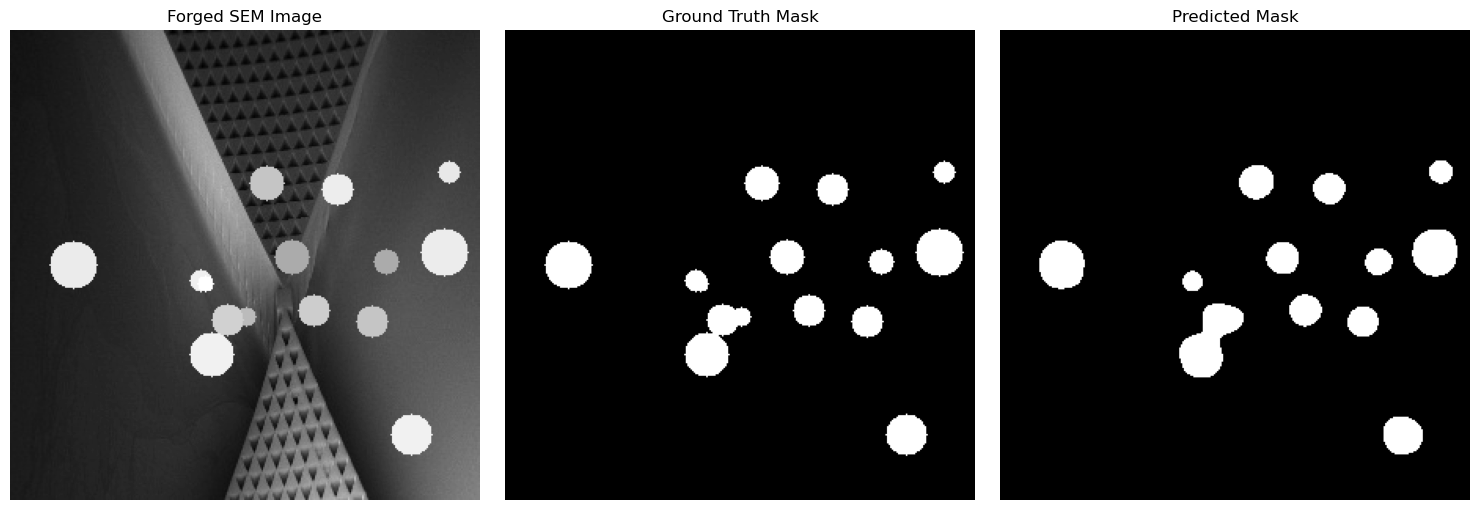

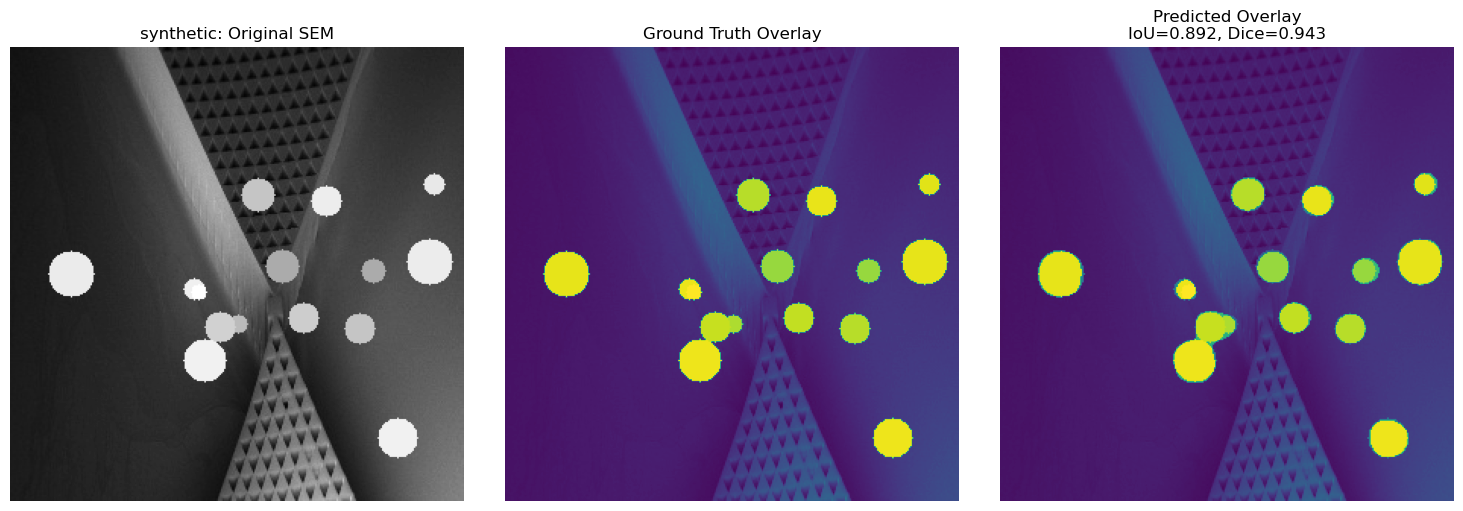

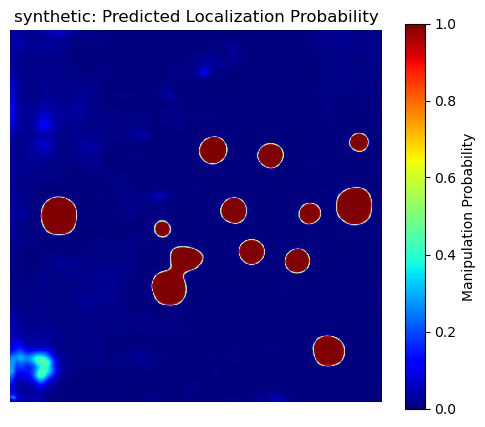


Class: contrast | IoU: 0.7764 | Dice: 0.8741


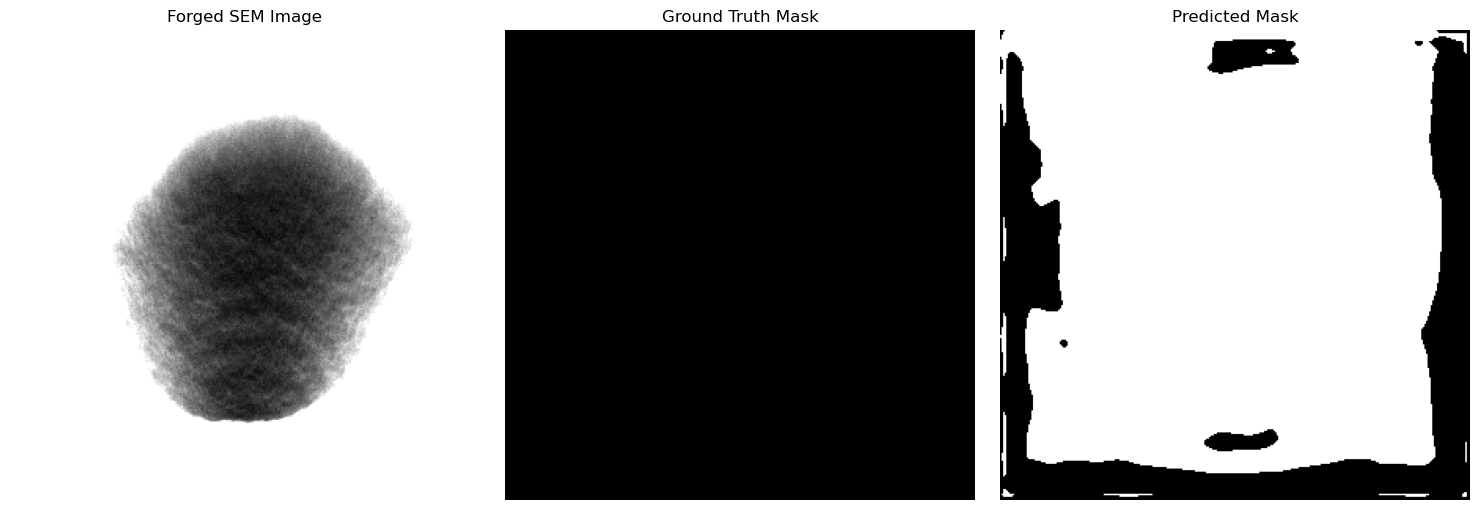

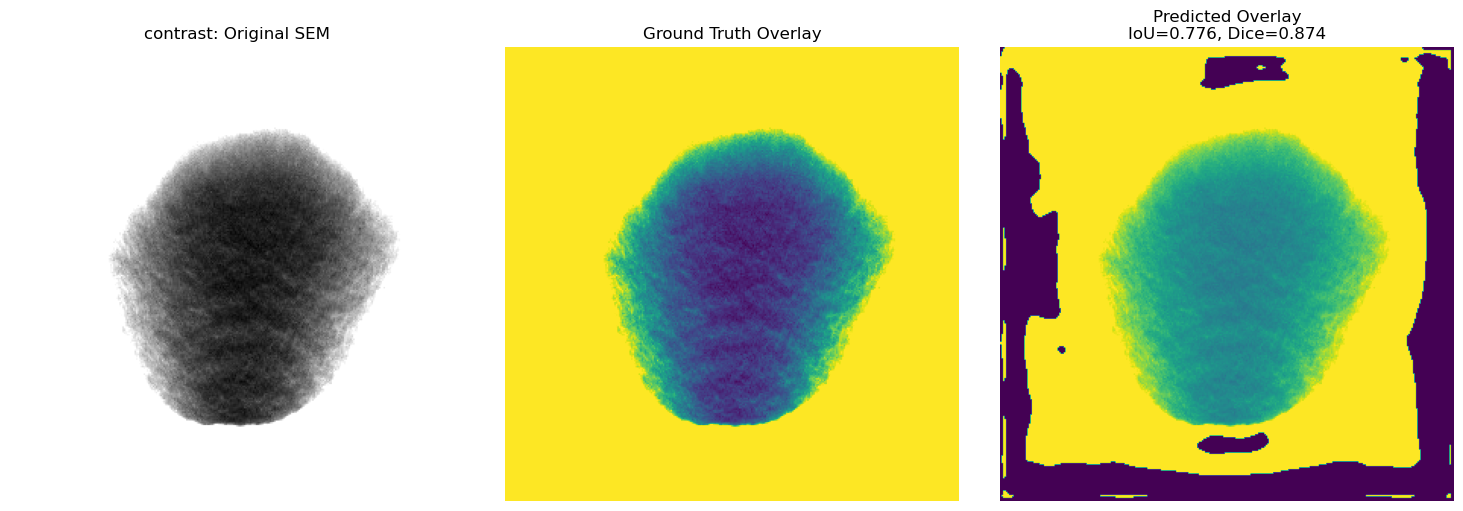

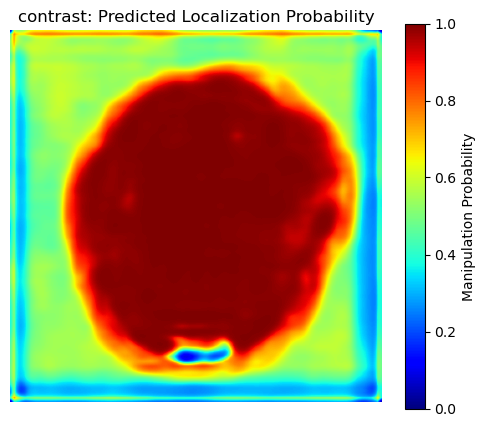


Class: copy_move | IoU: 0.3670 | Dice: 0.5370


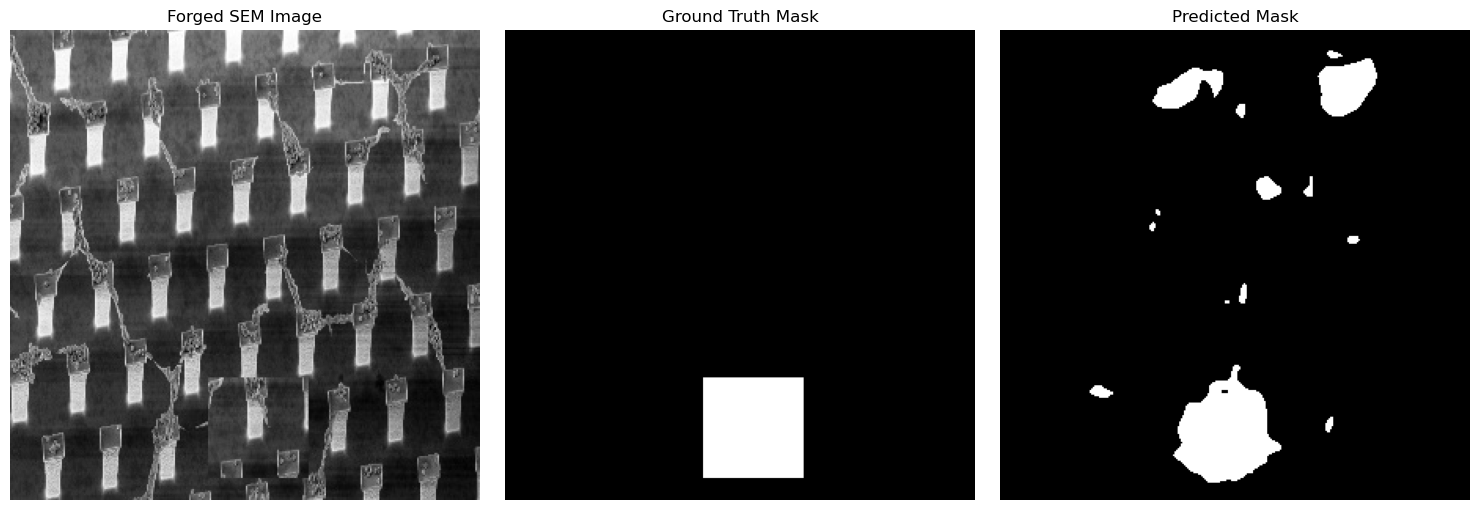

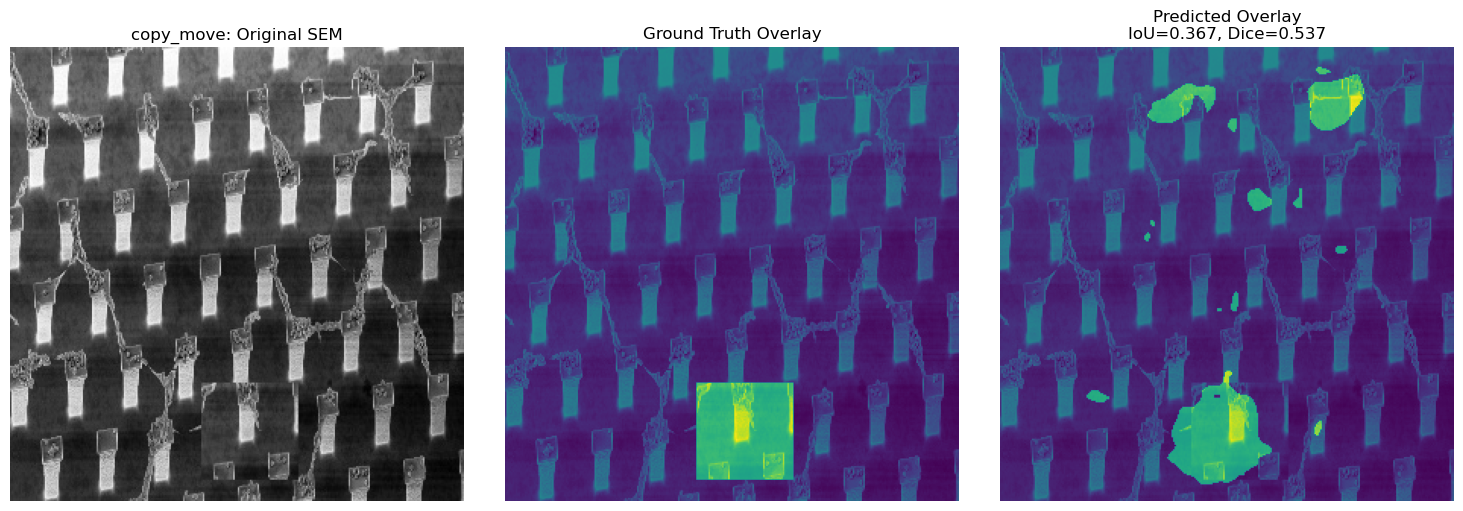

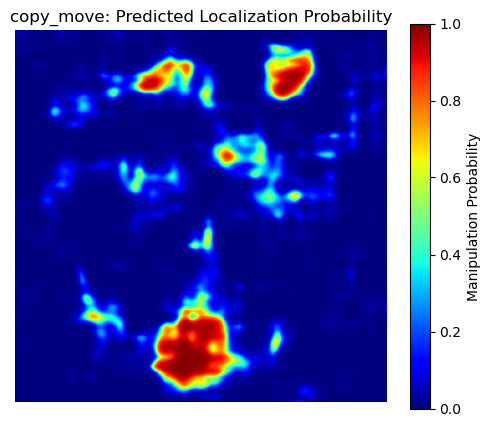


Class: splicing | IoU: 0.4050 | Dice: 0.5766


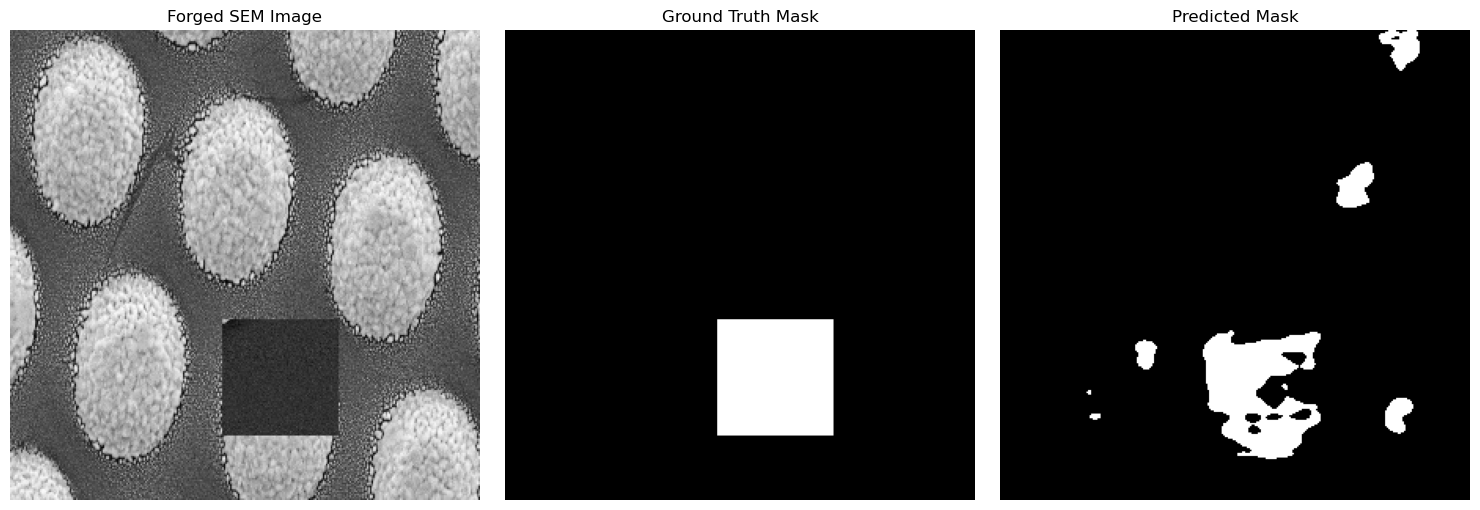

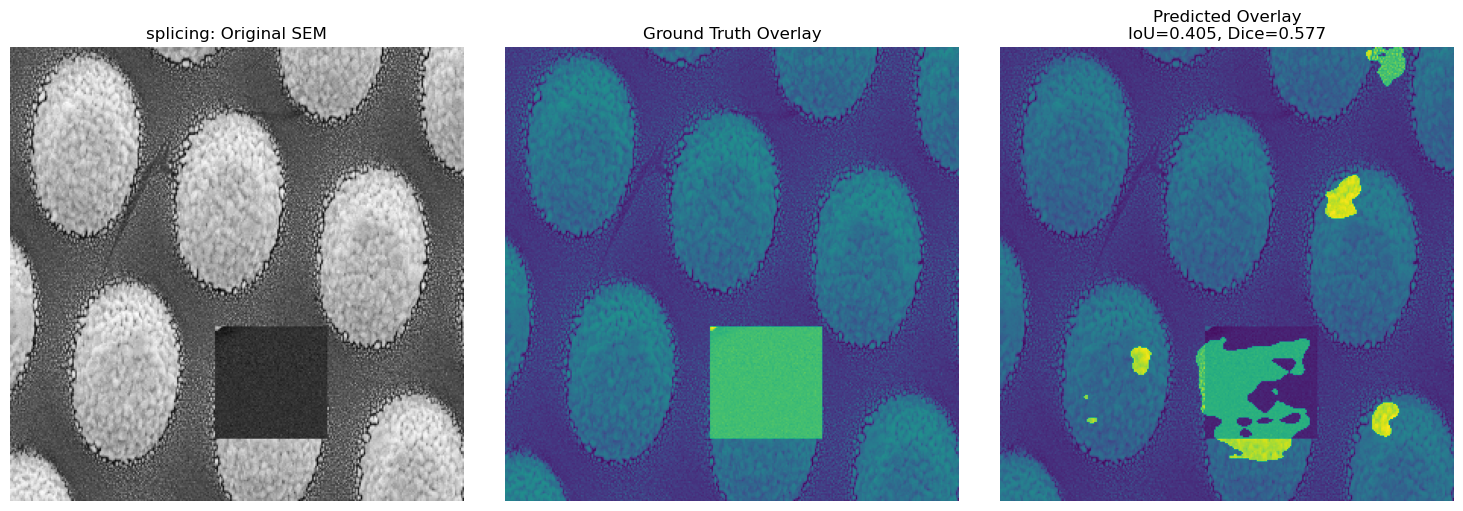

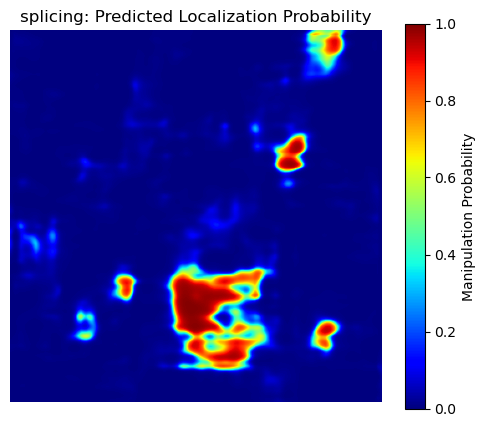


Classes visualized: ['copy_move', 'splicing', 'synthetic', 'contrast']


In [42]:
visualize_localization_by_class(
    model=model,
    test_loader=test_loader,
    device=device,
    threshold=0.5
)